# 🚀 Practice Day 64

**📅 Date:** 2026-11-12  
📁 Category: Phase 3 · NumPy+통계 응용 (Round 5/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Apply core statistics (proportions, confidence intervals, z-scores) to compare two online course curriculum versions
  (비율·신뢰구간·z-score 같은 통계 개념을 두 온라인 강좌 커리큘럼 버전 비교에 적용해보기)
- Find out whether Version B's higher completion rate and faster completion time are real, statistically meaningful differences
  (Version B의 높은 수료율과 빠른 수료 속도가 실제로 통계적으로 유의미한 차이인지 확인하기)

---
# 📂 Dataset

**Dataset Name:** Curriculum A/B Test — 온라인 강좌 커리큘럼 A/B 테스트 결과 / Online Course Curriculum A/B Test Results

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** Results from an online course curriculum A/B test with 400 students (Version A: 200, Version B: 200). Includes whether each student completed the course (0/1) and, for those who completed, how many days it took. Clean — no missing values beyond the expected NaN in completion_days for students who never completed, and no duplicates. The focus is on statistically comparing the two curriculum versions.
(400명이 수강한 온라인 강좌 커리큘럼 A/B 테스트 결과입니다(Version A: 200명, Version B: 200명). 각 학생의 수료 여부(0/1)와, 수료한 경우 수료까지 걸린 일수를 포함합니다. 수료하지 못한 학생의 completion_days가 결측인 것(예상된 결측, 오류 아님) 외에는 결측치·중복이 없습니다. 두 커리큘럼 버전을 통계적으로 비교하는 데 초점을 둡니다.)

## Dataset Preview

In [1]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate an online course curriculum A/B test: Version A vs Version B ---
n_a, n_b = 200, 200

completed_a = rng.binomial(1, 0.44, n_a)
completed_b = rng.binomial(1, 0.63, n_b)

# completion_days only applies to students who completed; NaN otherwise
days_a = np.where(completed_a == 1, np.clip(rng.normal(52, 16, n_a), 7, 120), np.nan)
days_b = np.where(completed_b == 1, np.clip(rng.normal(37, 13, n_b), 7, 120), np.nan)

df = pd.DataFrame({
    'student_id': [f'S{str(i+1).zfill(4)}' for i in range(n_a + n_b)],
    'version': ['A'] * n_a + ['B'] * n_b,
    'completed': np.concatenate([completed_a, completed_b]),
    'completion_days': np.round(np.concatenate([days_a, days_b]), 1)
})
df = df.sample(frac=1, random_state=99).reset_index(drop=True)

df.head(10)


,student_id,version,completed,completion_days
0,S0062,A,0,NaN
1,S0349,B,1,40.6
2,S0164,A,0,NaN
3,S0008,A,1,59.4
4,S0276,B,1,36.8
5,S0382,B,0,NaN
6,S0209,B,1,20.3
7,S0004,A,1,29.4
8,S0257,B,0,NaN
9,S0168,A,1,84.6


## Dataset Information

In [2]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   student_id       400 non-null    str    
 1   version          400 non-null    str    
 2   completed        400 non-null    int64  
 3   completion_days  211 non-null    float64
dtypes: float64(1), int64(1), str(2)
memory usage: 12.6 KB

Shape: (400, 4)


,student_id,version,completed,completion_days
count,400,400,400.000000,211.000000
unique,400,2,NaN,NaN
top,S0062,A,NaN,NaN
freq,1,200,NaN,NaN
mean,NaN,NaN,0.527500,43.514218
std,NaN,NaN,0.499868,15.623931
min,NaN,NaN,0.000000,7.000000
25%,NaN,NaN,0.000000,33.500000
50%,NaN,NaN,1.000000,42.800000
75%,NaN,NaN,1.000000,53.400000


---
# ❓ Business Questions

1. **(Analysis)** How much higher is Version B's completion rate compared to Version A, and does the 95% confidence interval for that difference exclude zero?
   (Version B의 수료율은 A보다 얼마나 높으며, 그 차이의 95% 신뢰구간은 0을 포함하지 않는가?)
2. **(Analysis)** Among students who completed, how much faster on average did Version B students finish, and is that difference statistically significant (z-score)?
   (수료한 학생 기준, Version B는 평균적으로 얼마나 더 빨리 수료했으며, 그 차이는 통계적으로 유의한가(z-score)?)
3. **(Analysis)** How does the spread (standard deviation) of completion time compare between the two versions?
   (두 버전의 수료 소요기간 산포(표준편차)는 어떻게 다른가?)
4. **(Visualization)** Compare the completion rate between the two versions.
   (두 버전의 수료율을 비교하면?)
5. **(Visualization)** Compare the distribution of completion time between the two versions.
   (두 버전의 수료 소요기간 분포를 비교하면?)

---
# 🔍 Data Cleaning Check


In [3]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
student_id           0
version              0
completed            0
completion_days    189
dtype: int64

Duplicate rows: 0

Dtypes
student_id             str
version                str
completed            int64
completion_days    float64
dtype: object

Column names
['student_id', 'version', 'completed', 'completion_days']

Text columns — unique counts
student_id    400
version         2
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** How much higher is Version B's completion rate compared to Version A, and does the 95% confidence interval for that difference exclude zero? (Version B 수료율은 A보다 얼마나 높은가? 95% 신뢰구간은 0을 포함하지 않는가?)

**Result:** Version B's completion rate is **62.50%** and Version A's is **43.00%**, so B is **19.50** percentage points higher. The 95% confidence interval for the difference is **[9.90%, 29.10%]**, which excludes zero.  
(Version B 수료율은 **62.50%**, Version A는 **43.00%**라서 B가 **19.50**%p 높습니다. 차이의 95% 신뢰구간은 **[9.90%, 29.10%]**이고 0을 포함하지 않습니다)

**Insight:** The lower end is **9.90%**, so B is clearly higher even in the cautious case. The standard error is **4.90%**.  
(하한이 **9.90%**라서 보수적으로 봐도 B가 분명히 높습니다. 표준오차는 **4.90%**)

In [4]:
# Question 1: completion rate by version, 95% CI for the difference in proportions

completion_rate_a = np.mean(df[df['version'] == 'A']['completed'])
completion_rate_b = np.mean(df[df['version'] == 'B']['completed'])
n_a = len(df[df['version'] == 'A'])
n_b = len(df[df['version'] == 'B'])
se_completion = np.sqrt((completion_rate_a * (1 - completion_rate_a) / n_a) + (completion_rate_b * (1 - completion_rate_b) / n_b))

completion_diff = completion_rate_b - completion_rate_a
margin = 1.96 * se_completion
ci_lower = completion_diff - margin
ci_upper = completion_diff + margin

print(f"Completion rate (Version A): {completion_rate_a:.2%}")
print(f"Completion rate (Version B): {completion_rate_b:.2%}")
print(f"Difference (B - A): {completion_diff:.2%}")
print(f"Standard error: {se_completion:.2%}")
print(f"95% Confidence interval: [{ci_lower:.2%}, {ci_upper:.2%}]")
print("Excludes zero:", ci_lower > 0 or ci_upper < 0)

Completion rate (Version A): 43.00%
Completion rate (Version B): 62.50%
Difference (B - A): 19.50%
Standard error: 4.90%
95% Confidence interval: [9.90%, 29.10%]
Excludes zero: True


## Question 2

**Question:** Among students who completed, how much faster on average did Version B students finish, and is that difference statistically significant? (수료한 학생 기준, B가 평균 얼마나 빨리 수료했는가? 유의한가?)

**Result:** Version B students finish in **37.09** days on average and Version A students in **52.85**, so B is **15.76** days faster. The z-score is **-8.02**.  
(Version B 학생은 평균 **37.09**일, Version A 학생은 **52.85**일 만에 수료해서 B가 **15.76**일 빠릅니다. z-score는 **-8.02**)

**Insight:** The absolute z-score is far above **1.96**, so the difference is significant at the 5% level. The standard error is **1.97** days.  
(z-score의 절댓값이 **1.96**보다 훨씬 커서 5% 수준에서 유의합니다. 표준오차는 **1.97**일)

In [5]:
# Question 2: mean completion_days (completed students only) by version, standard error, z-score

mean_days_a = np.mean(df[df['version'] == 'A']['completion_days'])
mean_days_b = np.mean(df[df['version'] == 'B']['completion_days'])
std_days_a = np.std(df[df['version'] == 'A']['completion_days'])
std_days_b = np.std(df[df['version'] == 'B']['completion_days'])
n_a = len(df[(df['version'] == 'A') & (df['completed'] == 1)])
n_b = len(df[(df['version'] == 'B') & (df['completed'] == 1)])
se_days = np.sqrt((std_days_a**2 / n_a) + (std_days_b**2 / n_b))
z_score = (mean_days_b - mean_days_a) / se_days

print(f"Mean completion days (Version A): {mean_days_a:.2f} days")
print(f"Mean completion days (Version B): {mean_days_b:.2f} days")
print(f"Standard deviation (Version A): {std_days_a:.2f} days")
print(f"Standard deviation (Version B): {std_days_b:.2f} days")
print(f"Standard error: {se_days:.2f} days")
print(f"Z-score: {z_score:.2f}")

Mean completion days (Version A): 52.85 days
Mean completion days (Version B): 37.09 days
Standard deviation (Version A): 15.09 days
Standard deviation (Version B): 12.34 days
Standard error: 1.97 days
Z-score: -8.02


## Question 3

**Question:** How does the spread (standard deviation) of completion time compare between the two versions? (두 버전의 수료 소요기간 산포는 어떻게 다른가?)

**Result:** The standard deviation of completion time is **15.09** days for Version A and **12.34** days for Version B, a gap of **2.75** days.  
(수료 소요기간 표준편차는 Version A **15.09**일, Version B **12.34**일로 **2.75**일 차이입니다)

**Insight:** Version B is faster and also more consistent, with a smaller spread than Version A.  
(Version B는 더 빠를 뿐 아니라 Version A보다 산포가 작아 더 일정합니다)

In [6]:
# Question 3: standard deviation of completion_days by version (completed students only)

std_days_a = np.std(df[df['version'] == 'A']['completion_days'])
std_days_b = np.std(df[df['version'] == 'B']['completion_days'])
print(f"Standard deviation (Version A): {std_days_a:.2f} days")
print(f"Standard deviation (Version B): {std_days_b:.2f} days")

Standard deviation (Version A): 15.09 days
Standard deviation (Version B): 12.34 days


---
# 📈 Visualization

**Chart 1:** Bar chart — completion rate by version (막대그래프: 버전별 수료율)

*Interpretation:* Version B's bar is **62.5%** and Version A's is **43.0%**, the **19.5** point gap from Question 1.  
(Version B 막대는 **62.5%**, Version A는 **43.0%**로, Q1의 **19.5**%p 차이와 같습니다)

---

**Chart 2:** Box plot (or histogram) — completion time distribution by version (박스플롯 또는 히스토그램: 버전별 수료 소요기간 분포)

*Interpretation:* Version B's median is about **39** days against about **54** for Version A, and B's box is narrower, matching its smaller standard deviation (**12.34** vs **15.09**).  
(Version B 중앙값은 약 **39**일, Version A는 약 **54**일이고 B의 박스가 더 좁아 더 작은 표준편차(**12.34** 대 **15.09**)와 맞습니다)

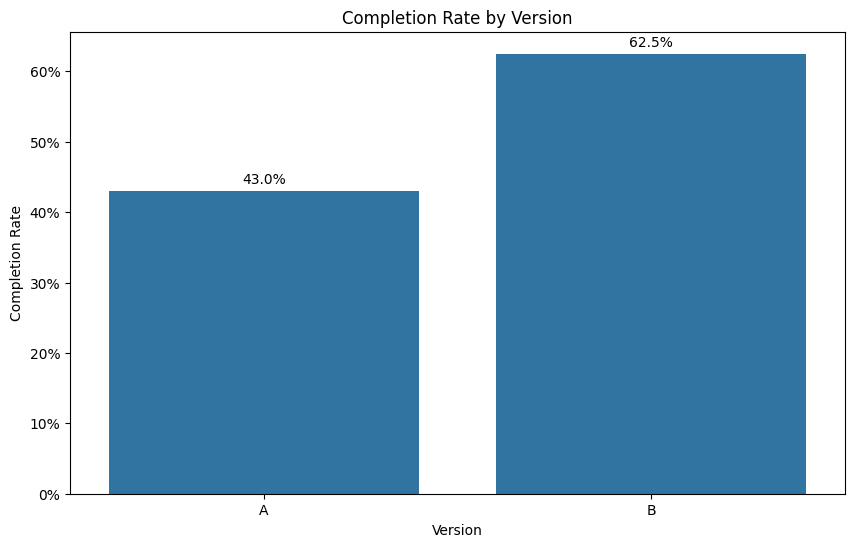

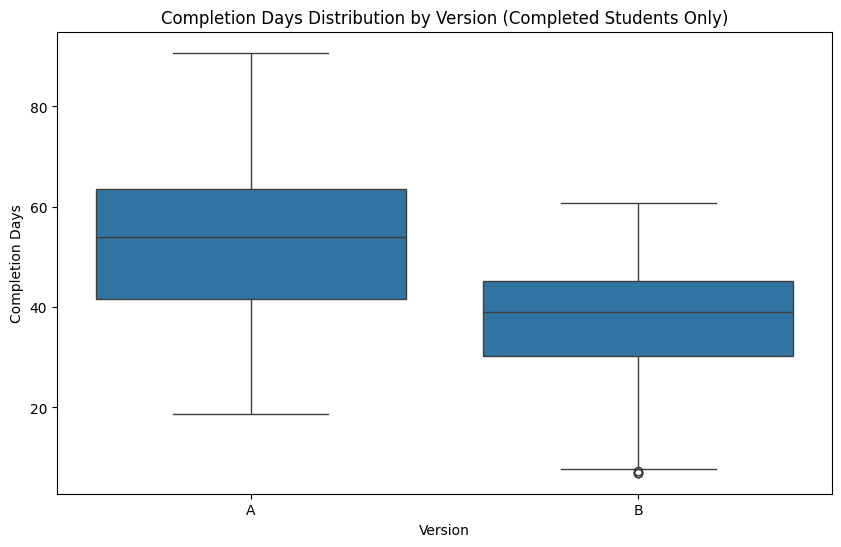

In [7]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# Chart 1: completion rate by version (bar)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='version', y='completed', data=df, order=['A', 'B'], errorbar=None, ax=ax)
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:.1%}' for v in container.datavalues], padding=3)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title('Completion Rate by Version')
ax.set_xlabel('Version')
ax.set_ylabel('Completion Rate')
plt.show()

# Chart 2: completion_days distribution by version, completed students only (box plot or histogram)
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(x='version', y='completion_days', data=df[df['completed'] == 1], order=['A', 'B'], ax=ax)
ax.set_title('Completion Days Distribution by Version (Completed Students Only)')
ax.set_xlabel('Version')
ax.set_ylabel('Completion Days')
plt.show()

---
# 💼 Business Insights
*What did I discover?*

- Version B's completion rate is **19.50** points higher (**62.50%** vs **43.00%**), and the 95% interval **[9.90%, 29.10%]** excludes zero.  
  (Version B 수료율이 **19.50**%p 높고(**62.50%** 대 **43.00%**), 95% 신뢰구간 **[9.90%, 29.10%]**은 0을 포함하지 않음)
- Students who complete Version B finish **15.76** days faster (**37.09** vs **52.85**), with a z-score of **-8.02**.  
  (Version B 수료 학생은 **15.76**일 더 빨리 수료(**37.09**일 대 **52.85**일), z-score **-8.02**)
- Version B's completion time is also less spread out (**12.34** vs **15.09** days).  
  (Version B의 수료 소요기간은 산포도 더 작음(**12.34**일 대 **15.09**일))  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Adopt Version B's curriculum, since it has a higher completion rate (**9.90%** to **29.10%** higher) and faster completion.  
   (수료율이 더 높고(**9.90%**~**29.10%**p 높음) 수료도 더 빠르므로 Version B 커리큘럼을 채택)
2. Report the completion-rate gap as **19.50** points with its interval, not as one number.  
   (수료율 차이는 숫자 하나가 아니라 **19.50**%p와 구간으로 보고)
3. Compare completion time only among students who completed, as the chart does.  
   (수료 소요기간은 차트처럼 수료한 학생끼리만 비교)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- 
- 
- 

---
# ✅ What I Learned
*Today's biggest lesson*

- The 95% interval for a difference of proportions is (B − A) ± 1.96 × SE, and zero outside it means a significant gap.  
  (비율 차이의 95% 구간은 (B − A) ± 1.96 × SE이고, 0이 밖에 있으면 유의한 차이)
- `completion_days` is NaN for students who did not complete, so the standard error uses `n` of completed students only (**211** in total).  
  (수료하지 않은 학생은 `completion_days`가 NaN이라 표준오차에는 수료한 학생 수 `n`만 씀(전체 **211**명))  

---
# 🧠 Reflection

**What was difficult?**  
Choosing the right `n` for the standard error in Question 2.  
(Q2에서 표준오차에 쓸 올바른 `n` 고르기)

**Why?**  
The mean and standard deviation skip NaN automatically, but `len()` of a group still counts every student.  
(평균과 표준편차는 NaN을 자동으로 건너뛰지만, 그룹의 `len()`은 학생 전체를 셈)

**How did I solve it?**  
I counted rows with `completed == 1` in each version, so the standard error is **1.97** days.  
(각 버전에서 `completed == 1`인 행을 세어 표준오차가 **1.97**일이 됨)

**What would I do differently next time?**  
Check that `n` counts the same rows as the mean and standard deviation.  
(`n`이 평균과 표준편차에 쓴 행과 같은 행을 세는지 확인하기)

---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
The interval, the z-score, and the spread all point to Version B. Its completion rate is **62.50%** against **43.00%**.  
(신뢰구간, z-score, 산포 모두 Version B를 가리킴. 수료율은 **62.50%** 대 **43.00%**)  

**Confidence**  
★★★★★★★☆☆☆  

**Difficulty**  
★★★☆☆☆☆☆☆☆  

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- 66개 파일 시리즈 완주! 🎉